In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

# 1. Setup the Hardware (GPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🚀 Status: Ready to launch on {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}")

🚀 Status: Ready to launch on NVIDIA GeForce GTX 1650


In [2]:
# 2. Define the Neural Network (The "Brain")
class PINN(nn.Module):
    def __init__(self):
        super(PINN, self).__init__()
        # Input: 2 neurons (x, t) -> Output: 1 neuron (u)
        self.net = nn.Sequential(
            nn.Linear(2, 20), nn.Tanh(),
            nn.Linear(20, 20), nn.Tanh(),
            nn.Linear(20, 20), nn.Tanh(),
            nn.Linear(20, 20), nn.Tanh(),
            nn.Linear(20, 20), nn.Tanh(),
            nn.Linear(20, 20), nn.Tanh(),
            nn.Linear(20, 20), nn.Tanh(),
            nn.Linear(20, 1)
        )

    def forward(self, x, t):
        inputs = torch.cat([x, t], axis=1)
        return self.net(inputs)

In [3]:
# 3. Define the Physics Equation (The "Teacher")
def physics_loss(model, x, t):
    x.requires_grad = True
    t.requires_grad = True
    
    u = model(x, t)
    
    # Calculate Derivatives (The gradients)
    u_x = torch.autograd.grad(u, x, torch.ones_like(u), create_graph=True)[0]
    u_t = torch.autograd.grad(u, t, torch.ones_like(u), create_graph=True)[0]
    u_xx = torch.autograd.grad(u_x, x, torch.ones_like(u_x), create_graph=True)[0]
    
    # Burgers' Equation: u_t + u*u_x - (0.01/pi)*u_xx = 0
    viscosity = 0.01 / np.pi
    f = u_t + (u * u_x) - (viscosity * u_xx)
    
    return torch.mean(f ** 2)

In [4]:
# --- A. generate the Training Data ---
N_b = 500    # Boundary points
N_f = 10000  # Physics points inside the domain

# Boundary: t=0 (Initial Condition: -sin(pi*x))
x_b = np.random.uniform(-1, 1, (N_b, 1))
t_b = np.zeros((N_b, 1))
u_b = -np.sin(np.pi * x_b)

# Boundary: Walls (x=-1 and x=1, u=0)
t_wall = np.random.uniform(0, 1, (N_b, 1))
x_left = -1 * np.ones((N_b, 1))
x_right = 1 * np.ones((N_b, 1))
u_wall = np.zeros((N_b, 1))

# Combine all "Known" data
X_boundary = np.vstack([x_b, x_left, x_right])
T_boundary = np.vstack([t_b, t_wall, t_wall])
U_boundary = np.vstack([u_b, u_wall, u_wall])

# Physics Points (Random spacetime coordinates)
X_physics = np.random.uniform(-1, 1, (N_f, 1))
T_physics = np.random.uniform(0, 1, (N_f, 1))

# Move to GPU
x_b_tensor = torch.tensor(X_boundary, dtype=torch.float32, device=device)
t_b_tensor = torch.tensor(T_boundary, dtype=torch.float32, device=device)
u_b_tensor = torch.tensor(U_boundary, dtype=torch.float32, device=device)
x_f_tensor = torch.tensor(X_physics, dtype=torch.float32, device=device)
t_f_tensor = torch.tensor(T_physics, dtype=torch.float32, device=device)

# --- B. The Training Loop ---
model = PINN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print("🧠 Training Neural Network on Physics...")
epochs = 5000 

for epoch in range(epochs):
    optimizer.zero_grad()
    
    # 1. Error on the boundary (Did it match the initial setup?)
    u_pred_b = model(x_b_tensor, t_b_tensor)
    loss_b = torch.mean((u_pred_b - u_b_tensor) ** 2)
    
    # 2. Error on the physics (Did it obey the equation?)
    loss_f = physics_loss(model, x_f_tensor, t_f_tensor)
    
    loss = loss_b + loss_f
    loss.backward()
    optimizer.step()
    
    if epoch % 500 == 0:
        print(f"Epoch {epoch}: Loss = {loss.item():.5f}")

print("✅ Training Complete!")

🧠 Training Neural Network on Physics...


C:\Users\MACHENIKE\AppData\Local\Programs\Python\Python314\Lib\site-packages\torch\autograd\graph.py:841: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\cuda\CublasHandlePool.cpp:270.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Epoch 0: Loss = 0.22669
Epoch 500: Loss = 0.05156
Epoch 1000: Loss = 0.03007
Epoch 1500: Loss = 0.01784
Epoch 2000: Loss = 0.01301
Epoch 2500: Loss = 0.04737
Epoch 3000: Loss = 0.00473
Epoch 3500: Loss = 0.00344
Epoch 4000: Loss = 0.00217
Epoch 4500: Loss = 0.00167
✅ Training Complete!


In [9]:
print(loss.item())

0.0013449322432279587


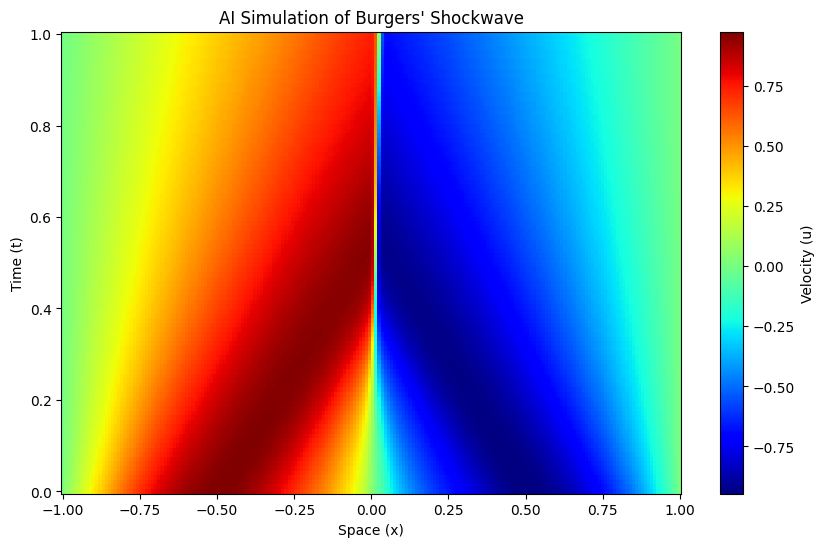

In [5]:
# Create a grid to visualize the result
x_plot = np.linspace(-1, 1, 200)
t_plot = np.linspace(0, 1, 100)
X, T = np.meshgrid(x_plot, t_plot)

# Flatten and send to GPU
X_flat = torch.tensor(X.flatten()[:, None], dtype=torch.float32, device=device)
T_flat = torch.tensor(T.flatten()[:, None], dtype=torch.float32, device=device)

# Predict
with torch.no_grad():
    u_pred = model(X_flat, T_flat)
    U_pred = u_pred.cpu().numpy().reshape(100, 200)

# Plot
plt.figure(figsize=(10, 6))
plt.pcolormesh(X, T, U_pred, cmap='jet', shading='auto')
plt.colorbar(label='Velocity (u)')
plt.xlabel('Space (x)')
plt.ylabel('Time (t)')
plt.title("AI Simulation of Burgers' Shockwave")
plt.show()